### Converting Image into the FFT of an Image

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

In [3]:
#Read Image
img = cv2.imread("D:\\Docs\\photo.jpeg")

In [4]:
#Check if image was loaded successfully
if img is None:
        print("Error: Image not found!")
        exit()

In [17]:
#Resize Image
img2 = cv2.resize(img, (500, 600))

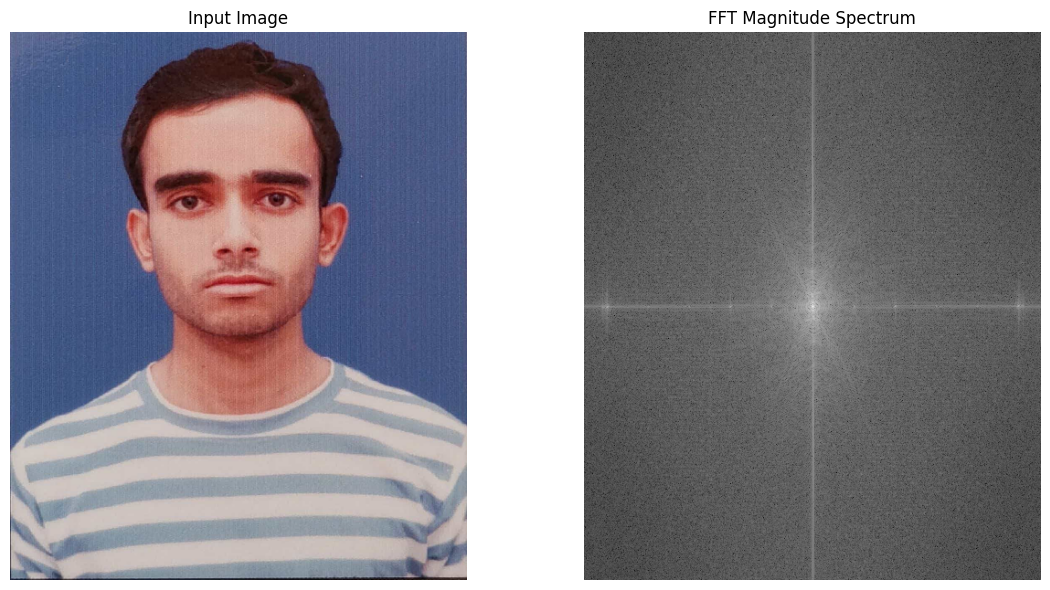

In [18]:
# Convert to grayscale for FFT
gray = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Compute DFT
dft = cv2.dft(np.float32(gray), flags=cv2.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)

# Compute magnitude spectrum
magnitude_spectrum = 20 * np.log(cv2.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)

# Convert BGR to RGB for display
img_rgb = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)

# Display results
fig = plt.figure(figsize=(12, 6))

ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(img_rgb)
ax1.set_title("Input Image")
ax1.axis("off")

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(magnitude_spectrum, cmap="gray")
ax2.set_title("FFT Magnitude Spectrum")
ax2.axis("off")

plt.tight_layout()
plt.show()